Obtain the control points from a curve

In [212]:
# Imports section
import numpy as np
from scipy.signal import butter, filtfilt
from music21 import converter, note

from scipy.interpolate import make_lsq_spline

import matplotlib.pyplot as plt

1st step: from MIDI to Frp

In [213]:
# Extract the pitches from 1 bar
def extract_pitches_1bar(notes):
    seq_len = 48 # hparams['seq_len_dataset']
    measeure_length = 4 # time signature is 4/4, so 4 beats per measure

    pitch_vector = np.zeros(seq_len, dtype=np.float32)

    onsets = []
    pitches = []

    for n in notes:
        if isinstance(n, note.Note):
            onsets.append(n.offset)
            pitches.append(n.pitch.midi)

    # Convert to numpy arrays
    onsets = np.array(onsets, dtype=np.float32)
    pitches = np.array(pitches, dtype=np.int16)

    # Convert note onset (offset in beats) to a grid position [0..47]
    norm_onsets = np.mod(onsets, measeure_length) / measeure_length
    quant_onsets = np.round(norm_onsets * (seq_len - 1)).astype(int)

    # Fill the pitch_vector
    # Sustain each note until the next onset
    for i, onset in enumerate(quant_onsets):
        if i + 1 < len(quant_onsets):
            end = quant_onsets[i + 1]
        else:
            end = seq_len
        pitch_vector[onset:end] = pitches[i]
    
    return pitch_vector, quant_onsets, pitches

# Compute the relative pitch function for 2nd bar
def compute_frp(onsets, pitches):
    # Definition of the constant variables
    frp_len = 512 # hparams['frp_len']
    filter_cutoff = 1/50
    filter_order = 5

    if len(onsets) == 0 or len(pitches) == 0:
        # Check empty arrays
        frp = np.zeros(frp_len, dtype=np.float32)

    else:
        # Piecewise-linear interpolation
        x = np.linspace(onsets.min(), onsets.max(), frp_len)
        y = np.interp(x, onsets, pitches)

        # Low-pass Butterworth filtering
        # to smooth the linear interpolation
        b, a = butter(filter_order, filter_cutoff, btype='low')
        y_smooth = filtfilt(b, a, y)

        # Normalization
        # Find midpoint in the curve range
        pitch_range = y_smooth.max() - y_smooth.min()
        middle_val = y_smooth.min() + pitch_range/2

        # Substract midpoint and divide by 12
        # 12 because 12 semitones = 1 octave
        frp = (y_smooth - middle_val) / 12.0

    # Return the function
    return frp.astype(np.float32)

# Process the 2 bars
def process_bars(midi_path):
    score = converter.parse(midi_path)

    # Extract 1st and 2nd bar from score
    bar1 = score.measure(1).flatten().notes
    bar2 = score.measure(2).flatten().notes
    bar2.show()

    # Convert bars into 48-step pitch vectors
    bar1_pitch_vector, _, _ = extract_pitches_1bar(bar1)
    bar2_pitch_vector, bar2_onsets, bar2_pitches = extract_pitches_1bar(bar2)

    # Compute the FRP for 2nd bar
    frp = compute_frp(bar2_onsets, bar2_pitches)

    # Return pitch vectors as numpy arrays
    return np.array(bar1_pitch_vector), np.array(bar2_pitch_vector), np.array(frp)

C:\Users\cristinj\AppData\Local\Temp\ipykernel_21972\1885437048.py:75: StreamIteratorInefficientWarning: show is not defined on StreamIterators. Call .stream() first for efficiency
  bar2.show()
c:\Users\cristinj\AppData\Local\anaconda3\envs\env\lib\site-packages\music21\musicxml\m21ToXml.py:428: MusicXMLWarning: <music21.stream.Score 0x26f92e53310> is not well-formed; see isWellFormedNotation()
  warnings.warn(f'{sc} is not well-formed; see isWellFormedNotation()',


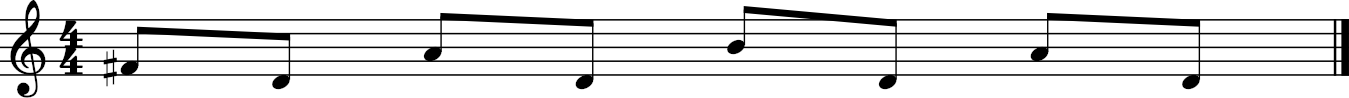

In [214]:
# Definition of the path to MIDI file
midi_path = "C:/Users/cristinj/OneDrive - Universitetet i Oslo/Documents/Project1/melodic-contour-generation-based-on-sketches/irishtunes_dataset/Cooley's_0_2bars_9.midi"
#midi_path = "C:/Users/cristinj/OneDrive - Universitetet i Oslo/Documents/Project1/melodic-contour-generation-based-on-sketches/synthetics_dataset/4.midi"

# Extract frp from 2nd bar
_, _, frp = process_bars(midi_path)

# print(frp)

2nd step: from curve to spline

In [215]:
# Define the spline parameters
x = np.linspace(0, 1, len(frp))
y = frp
control_points = 12 # Number of control points
k = 3  # Spline degree
num_internal_knots = control_points - k - 1 # 12-3-1 = 8 internal knots
t_internal = np.linspace(0, 1, num_internal_knots + 2)[1:-1]  # Internal knots vector
# Make the knot vector (k+1)-regular by adding boundary knots
t = np.r_[(x[0],)*(k+1),
          t_internal,
          (x[-1],)*(k+1)]

# Fit the spline
spline = make_lsq_spline(x, y, t, k)

# Evaluate spline
xs = np.linspace(0, 1, 500)
ys = spline(xs)

In [216]:
t, c, k = spline.t, spline.c, spline.k
print(t, c, k)
print(len(t))

[0.         0.         0.         0.         0.11111111 0.22222222
 0.33333333 0.44444444 0.55555556 0.66666667 0.77777778 0.88888889
 1.         1.         1.         1.        ] [-0.03305833 -0.00386311 -0.51824855 -0.02469962  0.36067632 -0.74687045
  0.71204    -0.31011272 -0.16781325  0.38913194 -0.25226939  0.00625243] 3
16


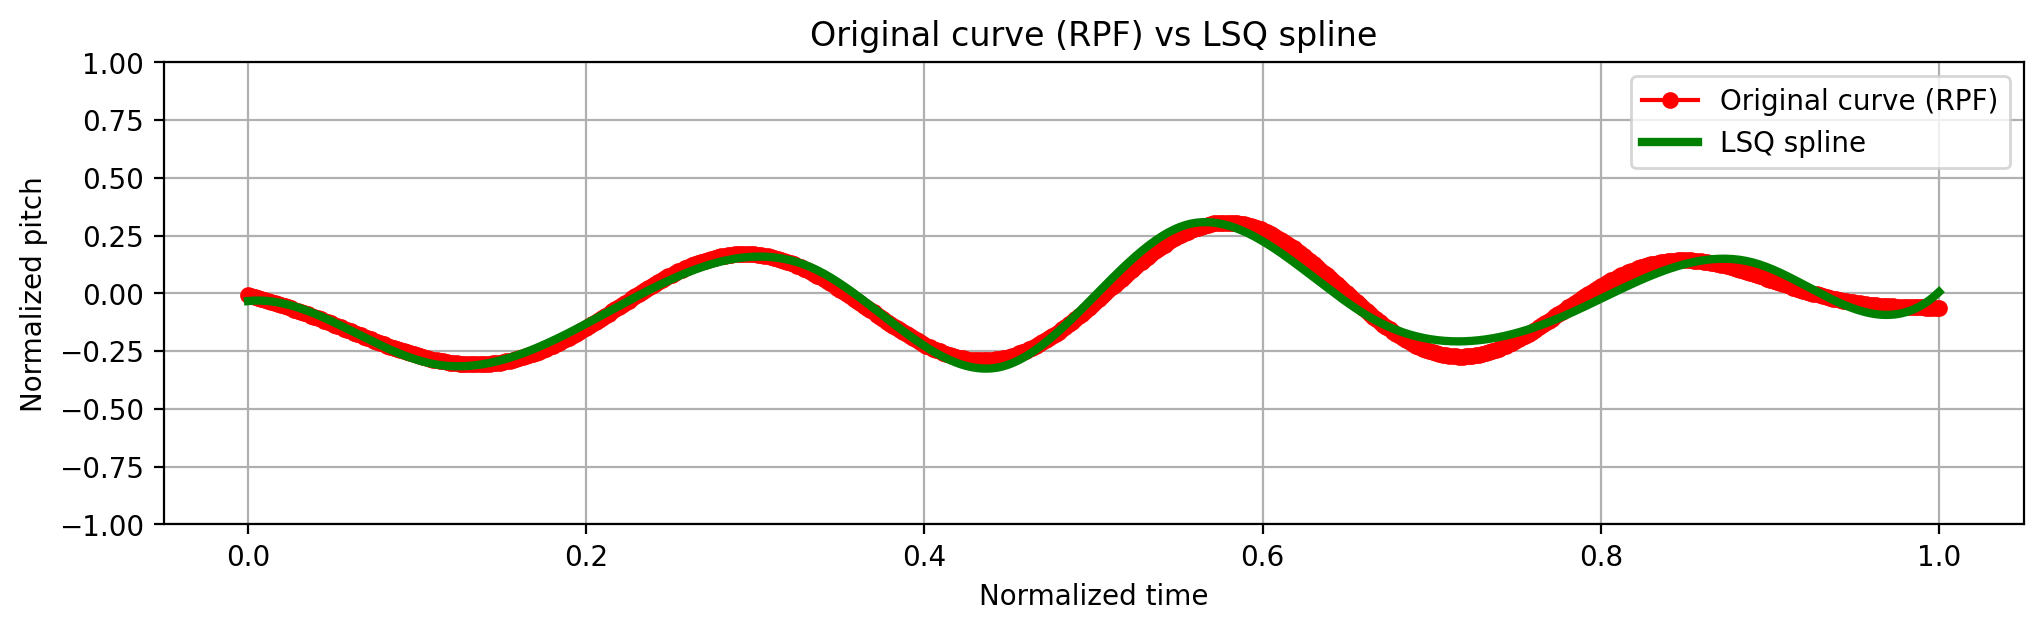

In [217]:
# Plot the results
plt.figure(figsize=(12,3))
plt.plot(x, y, 'ro-', ms=5, label='Original curve (RPF)')
plt.plot(xs, ys, 'g-', lw=3, label='LSQ spline')
plt.legend(loc='best')
plt.xlabel('Normalized time')
plt.ylabel("Normalized pitch")
plt.ylim(-1, 1)
plt.title('Original curve (RPF) vs LSQ spline')
plt.grid(True)
plt.show()